#**Preparation**

In [ ]:
!pip install --upgrade sympy

In [ ]:
import numpy as np
import random
import math
import matplotlib.pyplot as plt

from math import log
from sympy import symbols, solve
from scipy.optimize import fsolve, newton, bisect
from sympy import symbols, Matrix, I, exp, diag, sqrt, cot, csc, sin, asin, cos, pi, solve, re, eye, simplify, det
from sympy.printing import latex
from IPython.display import display, Math
from sympy.utilities.lambdify import lambdify
from scipy.interpolate import interp1d

#**Supressing $\mu \to e \gamma$**

Pada step ini dilakukan modifikasi matriks kopling Yukawa sehingga $\mu \to e \gamma$ diabaikan sehingga bisa dianggap 0 (nol).

In [ ]:
he1, he2, he3,hmu1, hmu2, hmu3,htau1, htau2, htau3 = symbols('he1 he2 he3 hmu1 hmu2 hmu3 htau1 htau2 htau3')
he2 = 0
hmu1 = 0
he3 = 0
htau2 = 0
h = Matrix([
    [he1, he2, he3],[hmu1, hmu2, hmu3], [htau1, htau2, htau3]])
h

Matrix([
[  he1,    0,     0],
[    0, hmu2,  hmu3],
[htau1,    0, htau3]])

In [ ]:
hT = h.transpose()

hT

Matrix([
[he1,    0, htau1],
[  0, hmu2,     0],
[  0, hmu3, htau3]])

In [ ]:
M1 = symbols('M1')
Mi = M1 * eye(3)

Mi
#M1=M2=M3, dengan M merupakan massa dari Neutrino berat N

Matrix([
[M1,  0,  0],
[ 0, M1,  0],
[ 0,  0, M1]])

In [ ]:
Mh = h * Mi * hT

Mh

Matrix([
[   M1*he1**2,                       0,              M1*he1*htau1],
[           0, M1*hmu2**2 + M1*hmu3**2,             M1*hmu3*htau3],
[M1*he1*htau1,           M1*hmu3*htau3, M1*htau1**2 + M1*htau3**2]])

In [ ]:
M_11 = Mh[0, 0]

result = Mh / M_11
M_v = simplify(result)

display(Math("M_v="+ latex(M_v)))

<IPython.core.display.Math object>

In [ ]:
a, b, c, d = symbols('a b c d')
M_v = M_v.subs({
    htau1/he1: a,
    hmu2/he1: d,
    hmu3/he1: b,
    htau3/he1: c})

M_v = M_v.subs({
    M_v[1, 1]: (b**2 + d**2),
    M_v[2, 2]: (a**2 + c**2)})

M_v = simplify(M_v)
display(Math("M_v = " + latex(M_v)))

#ini merupakan permisalan biar nanti menghitungnya mudah

<IPython.core.display.Math object>

#**Matriks Massa Neutrino dan R**
Disini memasukkan seluruh nilai yang diketahui dari data, sehingga matriks memiliki nilai

### Rasio Branching untuk $\tau$ Decay


#### Langkah 1: Definisi Variabel

- $ a = \frac{h_{\tau 1}}{h_{e1}}$
- $ d = \frac{h_{\mu 2}}{h_{e1}}$
- $ c = \frac{h_{\tau 3}}{h_{e 1}}$
- $ b = \frac{h_{\mu 3}}{h_{e1}}$

#### Langkah 2: Branching Ratio untuk $ \tau \to \mu \gamma \$

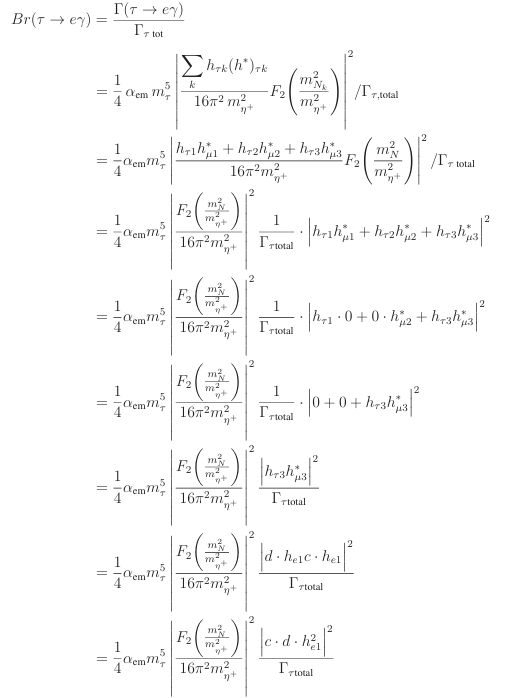

#### Langkah 3: Branching Ratio untuk $\tau \to e \gamma$
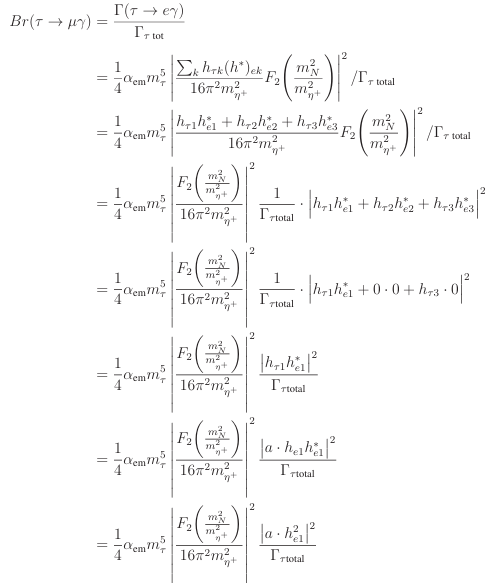


#### Langkah 4: Rasio antara Kedua Branching Ratios
$$
\frac{\text{BR}(\tau \to \mu \gamma)}{\text{BR}(\tau \to e \gamma)} = \frac{|h_{\tau 3}|^2 |h_{\mu 3}|^2}{|h_{\tau 1}|^2 |h_{e1}|^2}
$$

$$
\frac{\text{BR}(\tau \to \mu \gamma)}{\text{BR}(\tau \to e \gamma)} = \frac{|c|^2 |b|^2 / |h_{e1}|^4 }{|a|^2 |h_{e1}|^2 / |h_{e1}|^2}
$$

$$
\frac{\text{BR}(\tau \to \mu \gamma)}{\text{BR}(\tau \to e \gamma)} = \frac{|c|^2 |b|^2 / |h_{e1}|^4 }{|a|^2 |h_{e1}|^2 / |h_{e1}|^2}
$$

$$
\frac{\text{BR}(\tau \to \mu \gamma)}{\text{BR}(\tau \to e \gamma)} = \frac{|c|^2 |b|^2}{|a|^2}
$$


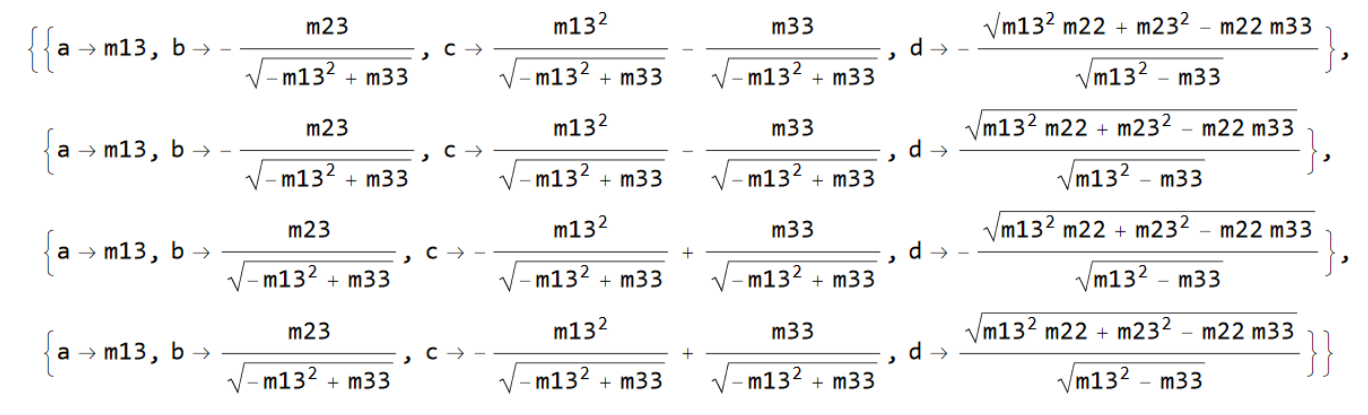

In [ ]:
datm = 0.0025  #eV^2
dsol = 0.000075  #eV^2
eps = 0.01
pi = np.pi
kount = 0
dat = np.array([])
M11 = np.array([])

while kount <= 2000000:
  m1 = 10**(np.random.uniform(-3, -1))
  m2 = np.sqrt(m1**2 + dsol)
  m3 = np.sqrt(m1**2 + datm)
  alpha = np.random.uniform(0,2*pi)
  beta = np.random.uniform(0,2*pi)
  delta = np.random.uniform(pi,2*pi)

  #mixing angles
  s12 = np.sqrt(0.308)
  s13 = np.sqrt(0.022)
  s23 = np.random.uniform(np.sqrt(0.41),np.sqrt(0.6))
  c12 = np.sqrt(1-s12**2)
  c13 = np.sqrt(1-s13**2)
  c23 = np.sqrt(1-s23**2)

  #PMNS
  U23 = np.array([[1, 0, 0],[0, c23, s23],[0, -s23, c23]])
  U13 = np.array([[c13, 0, s13*np.exp(-1j*delta)], [0, 1, 0],[-s13*(np.exp(1j*delta)), 0, c13]])
  U12 = np.array([[c12, s12, 0],[-s12, c12, 0],  [0, 0, 1]])

  #operasi
  U = np.matmul(np.matmul(U23,U13),U12)
  Us = np.conjugate(U)
  Ud = np.transpose(Us)
  Mnd = [[m1*np.exp(1j*alpha), 0, 0], [0, m2*np.exp(1j*beta),0], [0, 0, m3]]
  Mnu = np.matmul(np.matmul(Us,Mnd),Ud)
  Mv11 = np.real(Mnu[0,0])

  if Mv11 < 0.12:
      mnu = Mnu/Mnu[0,0]
      m12 = np.abs(mnu[0,1])
      m11 = mnu[0,0]

      J = np.imag(U[0,1]*np.conjugate(U[0,2])*np.conjugate(U[1,1])*U[1,2]) #ini untuk mengecek apakah terjadi pelanggaran CP atau tidak. Dalam model 3 flavor neutrino, J tergantung sudut campuran CP
      mtot = m1 + m2 + m3
      chisq =  (s23**2-0.45)**2/0.0175**2 + (J+0.0254)**2/0.00975**2

      if mtot < 0.56 and chisq <=8 and m12 <= 0.01:
        b = np.abs(mnu[1,2] / np.sqrt(-mnu[0,2]**2 + mnu[2,2]**2))
        c = np.abs((mnu[1,2]**2 - mnu[2,2]) /np.sqrt(-mnu[0,2]**2 + mnu[2,2]**2))
        dat = np.append(dat,np.array([
            m1,
            s23**2,
            delta*180/pi,
            np.abs(mnu[1,2]/mnu[0,2])**2,
            np.abs(mnu[1,2]), #cb
            np.abs(mnu[0,2]), #a
            b, #b
            c, #c
            np.abs(Mv11)
            ]))
  kount = kount + 1

if len(dat) == 0:
  print("Anda belum beruntung")
elif len(dat) > 0:
  dat_reshaped = dat.reshape(-1, 9)  #Mengubah menjadi bentuk (jumlah_baris, )

  print("Banyak data:", int(len(dat)/9))
  display(Math(r"\\[10pt]"))

  print("ratio = ", dat_reshaped[:, 3])
  display(Math(r"\\[10pt]"))

  print("|cb| = ", dat_reshaped[:, 4])
  display(Math(r"\\[10pt]"))

  print("|a| = ", dat_reshaped[:, 5])
  display(Math(r"\\[10pt]"))

  print("|b| = ", dat_reshaped[:, 6])
  display(Math(r"\\[10pt]"))

  print("|c| = ", dat_reshaped[:, 7])
  display(Math(r"\\[10pt]"))

  print("Mv11 = ", dat_reshaped[:, 8])
  display(Math(r"\\[10pt]"))

  print(len(dat_reshaped[:, 8]))

Banyak data: 147


<IPython.core.display.Math object>

ratio =  [9.74149426e+00 2.46527608e-01 7.88126440e-01 1.65006738e+02
 1.85229122e+01 3.74423812e-02 7.14732771e-01 1.57691276e-01
 6.52353726e-02 1.25112936e+01 1.13794199e+01 9.96954503e-01
 4.70903428e+00 1.46683168e+01 8.28876305e-02 7.48430985e+00
 2.96425326e+01 1.61169492e+03 7.25882619e-01 3.93270170e+00
 9.60993168e+00 5.42744919e+01 5.57735071e+01 1.97862470e-01
 1.08823870e+00 1.18291382e+01 2.17496170e-01 1.61859112e+01
 3.58388515e-01 3.56038185e+00 4.37873201e+00 1.10256478e-01
 1.89906896e+03 1.17822629e+03 1.60520498e+02 2.69537858e+01
 8.93731297e+02 1.30031866e+00 1.81491978e+01 3.28346902e+02
 5.91170881e-01 3.05782814e+00 5.19409819e+02 2.22304963e+00
 2.17744749e+01 1.23625712e+03 5.08960804e+01 2.73276471e-01
 1.72572838e+01 1.57897674e+02 4.88302108e+00 4.75995718e+00
 6.12103273e+00 2.40116202e+00 3.25690471e+02 1.54011370e+01
 2.02944539e+00 2.27070278e+01 9.16292513e-02 1.45263727e+01
 8.35879299e+00 3.14810257e+00 3.79683378e+00 8.44348703e+02
 1.67933125e+02

<IPython.core.display.Math object>

|cb| =  [2.74076733 0.22959088 0.18670958 0.58256994 0.35424404 0.07759705
 0.19058975 0.17128081 0.10518565 3.21996405 1.26154457 0.6646162
 0.22963254 1.1494539  0.13847235 1.82306987 1.58927257 0.96489098
 0.524166   1.0516617  4.56628109 0.54203639 0.66998238 0.20114511
 0.3820037  1.0291049  0.18403157 1.50129734 0.27696494 0.84310827
 0.50229309 0.11405451 0.89213673 1.04286446 0.69383704 1.67845181
 1.01535107 0.34610258 0.95510113 0.88907459 0.35537581 2.87287081
 0.90366273 0.64523978 1.97962599 0.62558017 0.8915977  0.18744137
 2.32003234 0.82645353 1.9623182  7.5789889  5.44687612 0.64213297
 1.05999817 2.56108652 0.56653049 0.59156295 0.1016436  1.22579568
 0.39221031 1.80558704 1.26369808 1.03144528 0.94300657 0.06976082
 0.16645548 0.13962891 4.42576934 0.97555708 0.39183972 3.25946095
 0.09266768 0.57160292 0.57505787 0.78326601 0.63519244 0.25596282
 0.64105612 0.79866626 0.67745307 0.74439757 1.11899005 0.16840531
 0.36991956 0.06380994 0.4250651  4.80136672 0.59354603

...

|c| =  [4.21426071 0.90718815 1.00711209 1.35603551 1.12068221 0.93764237
 1.00014633 0.9211766  0.93373316 4.69301508 2.07482978 0.71823062
 1.0416764  2.10085625 0.90999429 2.78946842 3.62465682 2.86898854
 0.83034902 1.35444643 5.71198194 1.30152425 1.48898082 0.91047915
 0.96871717 1.81466124 0.952807   2.83808719 0.89969499 1.17067808
 1.17241709 0.94944165 2.21936927 6.98297594 1.54055237 4.07763572
 3.85072344 1.01038232 1.92429256 2.13406366 0.91922059 0.92716493
 2.26118088 1.02674987 4.44485379 1.43178521 1.86834309 0.95885691
 4.27192587 1.82609076 1.9524509  6.88016977 5.47181278 1.08578699
 3.66537576 4.19315998 1.11485093 1.32122473 0.95250841 2.4007665
 1.124269   0.93539569 1.50677963 4.37119342 2.18150015 0.9308285
 0.97172407 0.92985082 3.05415651 2.52796912 1.12735336 5.1259238
 0.93051136 0.73272516 1.32777454 1.52471776 0.79671675 1.04032984
 1.31085771 1.76971508 0.71174734 1.12168132 2.35496612 0.9373645
 0.88080715 0.94245012 1.11431483 3.71092297 0.76768438 3.4

<IPython.core.display.Math object>

Mv11 =  [7.10664369e-03 4.34371051e-02 9.37938655e-02 3.09238848e-02
 6.89543506e-02 8.86403252e-02 7.97166496e-02 5.52275585e-02
 8.01382700e-02 8.60485379e-03 6.72706024e-05 2.28555813e-02
 8.94641062e-02 3.25119452e-03 6.39385022e-02 2.48993311e-03
 1.76752802e-02 6.71282682e-02 2.44153184e-02 9.89348234e-03
 6.00577338e-03 4.14974567e-02 2.31591695e-02 5.08951006e-02
 4.00276987e-02 3.20061951e-03 5.47468900e-02 4.12855136e-03
 4.28112884e-02 2.13844788e-02 3.98211282e-02 7.52334991e-02
 4.02900650e-02 9.49777530e-02 1.21046105e-02 1.90218197e-02
 7.94094221e-02 3.73760873e-02 6.79974877e-03 3.42148766e-02
 4.06863295e-02 6.32274053e-03 3.97545609e-02 2.76154267e-02
 1.63138351e-02 2.80206659e-02 1.13256410e-03 6.78761425e-02
 1.23629594e-02 1.11979445e-03 3.53137618e-03 2.07937106e-04
 1.48700164e-03 2.01619640e-02 5.44585690e-02 1.07348201e-02
 2.26631014e-02 3.13184633e-02 8.17388560e-02 1.46669957e-03
 5.35983390e-02 1.13462546e-02 7.26899786e-03 7.83420802e-02
 1.85611177e-02 

<IPython.core.display.Math object>

147


In [ ]:
newlist = []
row = int(len(dat)/9)
col = 9

for i in range(row):
  list_temp = []
  for k in range(col):
    list_temp.append(dat[i*col + k])
  newlist.append(list_temp)
qq = np.array(newlist)
print(qq)
print(len(qq))

[[9.88394623e-03 4.88130585e-01 2.36181823e+02 ... 1.17386016e+00
  4.21426071e+00 7.10664369e-03]
 [4.87429724e-02 4.32723737e-01 2.39006112e+02 ... 1.70769319e-01
  9.07188153e-01 4.34371051e-02]
 [9.74848481e-02 4.72892310e-01 3.37902840e+02 ... 1.74545517e-01
  1.00711209e+00 9.37938655e-02]
 ...
 [1.75174639e-02 4.67713627e-01 2.27930560e+02 ... 5.05332864e-01
  7.47060363e-01 1.17851827e-02]
 [8.07813076e-02 4.76116227e-01 2.38520186e+02 ... 9.47363310e-02
  9.28605599e-01 6.99569318e-02]
 [5.47084001e-02 4.10337349e-01 2.21117797e+02 ... 1.00755990e+00
  1.84681749e+00 6.78060414e-03]]
147


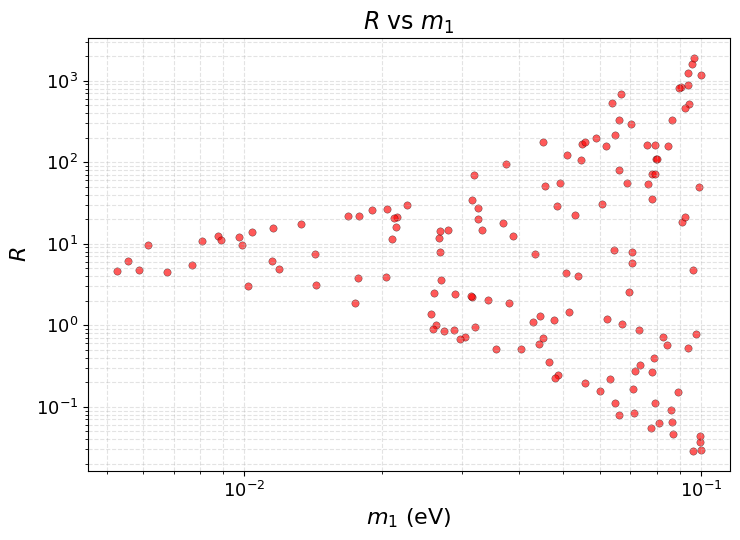

In [ ]:
plt.figure(figsize=(7.5, 5.5))

plt.scatter(
    qq[:, 0], qq[:, 3],
    s=28,
    color='red',
    alpha=0.65,
    edgecolors='black',
    linewidths=0.3
)

plt.xscale('log')
plt.yscale('log')

plt.xlabel(r'$m_1$ (eV)', fontsize=16)
plt.ylabel(r'$R$', fontsize=16)
plt.title(r'$R$ vs $m_1$', fontsize=17)

plt.grid(True, which='both', linestyle='--', alpha=0.35)

plt.tick_params(axis='both', which='major', labelsize=13)
plt.tick_params(axis='both', which='minor', labelsize=11)

plt.tight_layout()
plt.show()

# **Mencari nilai $h_{e1}$** (variasi [link text](https://arxiv.org/pdf/1908.08215))

---



---



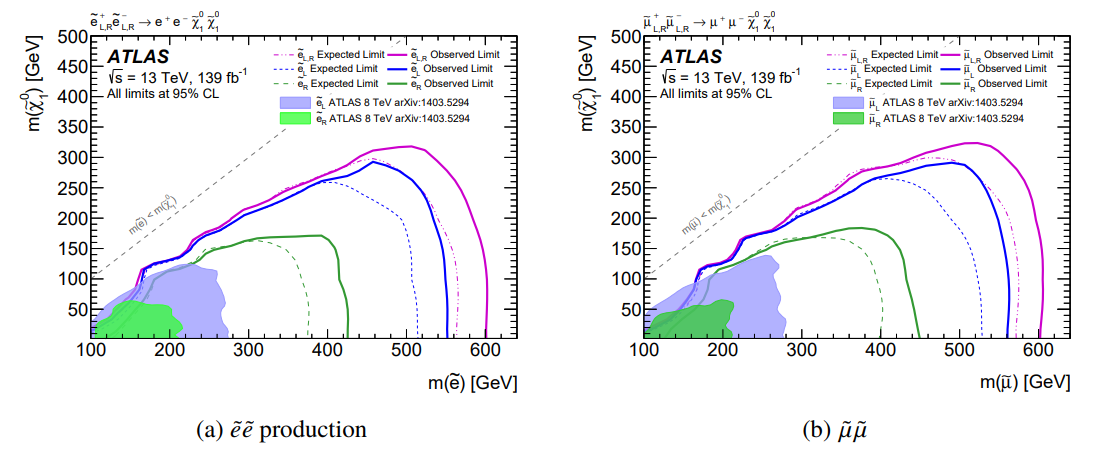

## Merge hasil $h_{e1}$ dari $Br (\tau \to \mu \gamma)$ dan ${Br (\tau \to e \gamma)}$

In [ ]:
conv = 1/(6.58*10**(-25))
alpha = 1/137
mtau = 1.777 * 10**9 #eV
mN = np.random.uniform(350 * 10**9 , 1000 * 10**9)
meta = 560 * 10**9 #eV
tau = 2.9*10**(-13)*conv
h11mu_values = []
h11e_values = []
a_values = []
m1_values = []
cb_values = []

#Fungsi F2
def F2(x):
    return (1 - 6*x + 3*x**2 + 2*x**3 - 6*x**2 * log(x)) / (6 * (1 - x)**4)

#Fungsi BR(tau -> mu)
def brtaumu(cb, h11):
    y = cb * h11**2
    F2_value = F2(mN**2 / meta**2)
    term = abs((y / (16 * pi**2 * meta**2)) * F2_value)**2
    return 1/4 * alpha * mtau**5 * term * tau

#Fungsi BR(tau -> e)
def brtaue(a, h11):
    y = a * h11**2
    F2_value = F2(mN**2 / meta**2)
    term = abs((y / (16 * pi**2 * meta**2)) * F2_value)**2
    return 1/4 * alpha * mtau**5 * term * tau

h11 = symbols('h11', real=True, positive=True)

for i, entry in enumerate(dat_reshaped):
    cb = entry[4]
    a = entry[5]
    m1 = entry[0]
    brmu = brtaumu(cb, h11) - 4.4 * 10**(-8)
    bre = brtaue(a, h11) - 3.3 * 10**(-8)
    solmu = solve(brmu, h11)
    sole = solve(bre, h11)
    if solmu and sole:
        h11mu = (solmu[0])
        h11e = (sole[0])
        h11mu_values.append(h11mu)
        h11e_values.append(h11e)
        a_values.append(a)
        cb_values.append(cb)
        m1_values.append(m1)

        print(f"h11 mu: {h11mu:.6e} for cb: {cb:.6e}, m1:{m1:.6e}, mN:{mN:.6e}, meta:{meta:.6e}")
        print(f"h11 e: {h11e:.6e} for a: {a:.6e}, m1:{m1:.6e}, mN:{mN:.6e}, meta:{meta:.6e}")

print(len(h11mu_values), len(h11e_values))

h11 mu: 3.598355e-3 for cb: 2.740767e+00, m1:9.883946e-03, mN:6.109148e+11, meta:5.600000e+11
h11 e: 5.915967e-3 for a: 8.781311e-01, m1:9.883946e-03, mN:6.109148e+11, meta:5.600000e+11
h11 mu: 1.243262e-2 for cb: 2.295909e-01, m1:4.874297e-02, mN:6.109148e+11, meta:5.600000e+11
h11 e: 8.152570e-3 for a: 4.624043e-01, m1:4.874297e-02, mN:6.109148e+11, meta:5.600000e+11
h11 mu: 1.378659e-2 for cb: 1.867096e-01, m1:9.748485e-02, mN:6.109148e+11, meta:5.600000e+11
h11 e: 1.208846e-2 for a: 2.103142e-01, m1:9.748485e-02, mN:6.109148e+11, meta:5.600000e+11
h11 mu: 7.804877e-3 for cb: 5.825699e-01, m1:7.616192e-02, mN:6.109148e+11, meta:5.600000e+11
h11 e: 2.603196e-2 for a: 4.535208e-02, m1:7.616192e-02, mN:6.109148e+11, meta:5.600000e+11
h11 mu: 1.000896e-2 for cb: 3.542440e-01, m1:9.094892e-02, mN:6.109148e+11, meta:5.600000e+11
h11 e: 1.932331e-2 for a: 8.230911e-02, m1:9.094892e-02, mN:6.109148e+11, meta:5.600000e+11
h11 mu: 2.138541e-2 for cb: 7.759705e-02, m1:9.947662e-02, mN:6.109148

In [ ]:
import pandas as pd
results = {'cb': cb_values,'a': a_values, 'm1': m1_values, 'mN': [mN] * len(cb_values), 'meta': [meta] * len(cb_values), 'h11_mu': h11mu_values, 'h11_e': h11e_values}
results_df = pd.DataFrame(results) #DataFrame pandas untuk membuat tabel
print(results_df)

           cb         a        m1            mN          meta  \
0    2.740767  0.878131  0.009884  6.109148e+11  560000000000   
1    0.229591  0.462404  0.048743  6.109148e+11  560000000000   
2    0.186710  0.210314  0.097485  6.109148e+11  560000000000   
3    0.582570  0.045352  0.076162  6.109148e+11  560000000000   
4    0.354244  0.082309  0.090949  6.109148e+11  560000000000   
..        ...       ...       ...           ...           ...   
142  0.137731  0.485912  0.066227  6.109148e+11  560000000000   
143  1.219322  0.091292  0.045196  6.109148e+11  560000000000   
144  1.217630  0.893814  0.017517  6.109148e+11  560000000000   
145  0.111970  0.442932  0.080781  6.109148e+11  560000000000   
146  0.854085  0.082469  0.054708  6.109148e+11  560000000000   

                  h11_mu                h11_e  
0    0.00359835528265461  0.00591596712111174  
1     0.0124326242177374  0.00815256956913633  
2     0.0137865887731625   0.0120884637311116  
3    0.00780487746705389   

In [ ]:
intervals = np.arange(0, 0.11, 0.01) #interval untuk m1
max_h11mu = []
max_h11e = []

for lower, upper in zip(intervals[:-1], intervals[1:]):
    interval_data = results_df[(results_df['m1'] >= lower) & (results_df['m1'] < upper)]
    if not interval_data.empty:
        max_h11mu_idx = interval_data['h11_mu'].idxmax()
        max_h11e_idx = interval_data['h11_e'].idxmax()

        max_h11mu.append(interval_data.loc[max_h11mu_idx, ['m1', 'h11_mu']])
        max_h11e.append(interval_data.loc[max_h11e_idx, ['m1', 'h11_e']])

#dataframe
max_h11mu_df = pd.DataFrame(max_h11mu)
max_h11e_df = pd.DataFrame(max_h11e)
if not max_h11mu_df.empty and not max_h11e_df.empty:
    m1_min = min(max_h11mu_df['m1'].min(),
                 max_h11e_df['m1'].min())
    m1_max = max(max_h11mu_df['m1'].max(),
                 max_h11e_df['m1'].max())
    m1_fine = np.linspace(m1_min, m1_max, len(dat_reshaped))

    #interpolasi
    interp_mu = interp1d(
        max_h11mu_df['m1'],
        max_h11mu_df['h11_mu'],
        kind='cubic',
        bounds_error=False,
        fill_value=np.nan
    )

    interp_e = interp1d(
        max_h11e_df['m1'],
        max_h11e_df['h11_e'],
        kind='cubic',
        bounds_error=False,
        fill_value=np.nan
    )

    h11mu_interp = interp_mu(m1_fine)
    h11e_interp = interp_e(m1_fine)

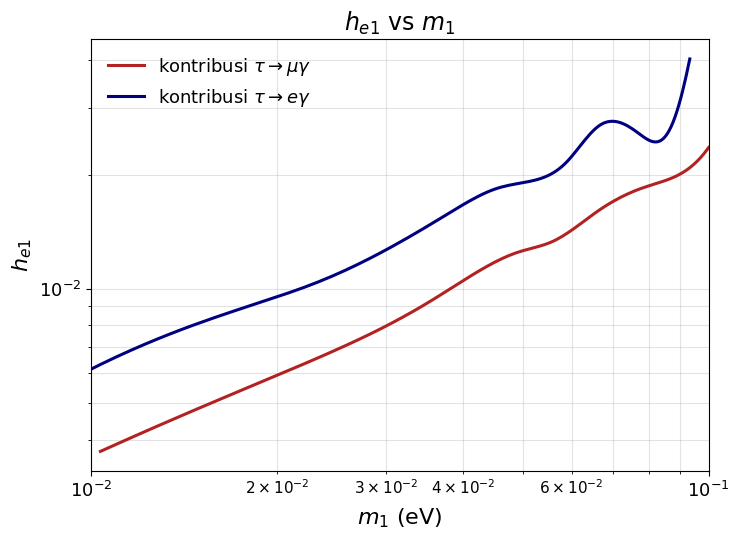

In [ ]:
plt.figure(figsize=(7.5, 5.5))

plt.plot(
    m1_fine, h11mu_interp,
    color='firebrick',
    linewidth=2.2,
    linestyle='-',
    label=r'kontribusi $\tau \to \mu \gamma$'
)

plt.plot(
    m1_fine, h11e_interp,
    color='navy',
    linewidth=2.2,
    linestyle='-',
    label=r'kontribusi $\tau \to e \gamma$'
)

plt.xscale('log')
plt.yscale('log')

plt.xlabel(r'$m_1$ (eV)', fontsize=16)
plt.ylabel(r'$h_{e1}$', fontsize=16)
plt.title(r'$h_{e1}$ vs $m_1$', fontsize=17)

plt.legend(
    fontsize=13,
    frameon=False,
    loc='best'
)

plt.grid(True, which='both', linestyle='-', alpha=0.35)

plt.tick_params(axis='both', which='major', labelsize=13)
plt.tick_params(axis='both', which='minor', labelsize=11)

plt.xlim(1e-2, 1e-1)

plt.tight_layout()
plt.show()

In [ ]:
h11mu_interp

array([       nan, 0.00372193, 0.00388337, 0.00404096, 0.00419492,
       0.00434544, 0.00449273, 0.00463699, 0.00477843, 0.00491725,
       0.00505365, 0.00518784, 0.00532003, 0.00545041, 0.00557919,
       0.00570658, 0.00583278, 0.00595799, 0.00608242, 0.00620627,
       0.00632975, 0.00645306, 0.0065764 , 0.00669998, 0.00682401,
       0.00694868, 0.0070742 , 0.00720078, 0.00732862, 0.00745792,
       0.00758889, 0.00772174, 0.00785665, 0.00799384, 0.00813337,
       0.0082753 , 0.00841967, 0.00856652, 0.0087159 , 0.00886785,
       0.00902242, 0.00917965, 0.00933958, 0.0095021 , 0.00966671,
       0.00983282, 0.00999986, 0.01016725, 0.01033441, 0.01050077,
       0.01066574, 0.01082875, 0.01098923, 0.01114659, 0.01130025,
       0.01144965, 0.0115942 , 0.01173333, 0.01186645, 0.011993  ,
       0.01211238, 0.01222404, 0.01232738, 0.01242183, 0.0125071 ,
       0.01258457, 0.0126562 , 0.01272397, 0.01278985, 0.0128558 ,
       0.01292379, 0.0129958 , 0.01307379, 0.01315974, 0.01325

In [ ]:
len(h11mu_interp)

147

In [ ]:
print("shape h11mu_interp =", np.shape(h11mu_interp))

shape h11mu_interp = (147,)


# **Kontribusi $\lambda_5$**

In [ ]:
lambda5_values = []
h11mu_values = []
Mv11_values = []
m1_values = []

m0 = 100 * 10**9 #eV
M1 = 1000 * 10**9 #eV
v = 174 * 10**9 #eV
m0_squared = m0**2
M1_squared = M1**2
pi = np.pi

def ln(m0_squared, M1_squared):
    return np.log(m0_squared / M1_squared)

def M11_func(lambda5, h11mu, m0_squared, M1_squared, v, pi):
    pi = np.pi
    term = 1 - ((M1_squared / (m0_squared - M1_squared)) * ln(m0_squared, M1_squared))
    return ((v**2 * lambda5 * M1 * h11mu**2) / (16 * pi**2 * (m0_squared - M1_squared))) * term

lambda5 = symbols('lambda5', real=True)

for i, entry in enumerate(dat_reshaped):
    h11mu = float(h11mu_interp[i])
    m1 = float(entry[0])
    Mv11 = float(entry[6])

    Mv = M11_func(lambda5, h11mu, m0_squared, M1_squared, v, pi) - Mv11
    sol = solve(Mv, lambda5)

    valid_solution = None
    for s in sol:
        #if s.is_real and float(s) > 0:     #hanya ambil solusi real & positif
        if s.is_real:
            valid_solution = float(s)
            break
    if valid_solution is not None:
        lambda5_values.append(valid_solution)
        h11mu_values.append(h11mu)
        m1_values.append(m1)
        Mv11_values.append(Mv11)
        print(f"lambda5={valid_solution:.6e}, h11mu={h11mu:.6e}")

print("total lambda5", len(lambda5_values))
print("total he1:", len(h11mu_values))

lambda5=1.743160e-05, h11mu=3.721926e-03
lambda5=1.636645e-05, h11mu=3.883367e-03
lambda5=5.342013e-05, h11mu=4.040965e-03
lambda5=2.789766e-05, h11mu=4.194921e-03
lambda5=5.106651e-06, h11mu=4.345442e-03
lambda5=1.212369e-05, h11mu=4.492731e-03
lambda5=8.916458e-06, h11mu=4.636992e-03
lambda5=5.563284e-06, h11mu=4.778430e-03
lambda5=6.916449e-05, h11mu=4.917248e-03
lambda5=4.822065e-05, h11mu=5.053650e-03
lambda5=1.839008e-05, h11mu=5.187842e-03
lambda5=1.093251e-05, h11mu=5.320026e-03
lambda5=4.685794e-05, h11mu=5.450408e-03
lambda5=5.140212e-06, h11mu=5.579191e-03
lambda5=4.349293e-05, h11mu=5.706579e-03
lambda5=6.837910e-05, h11mu=5.832778e-03
lambda5=8.215017e-05, h11mu=5.957989e-03
lambda5=1.191164e-05, h11mu=6.082419e-03
lambda5=2.114458e-05, h11mu=6.206271e-03
lambda5=3.723320e-05, h11mu=6.329750e-03
lambda5=1.897317e-05, h11mu=6.453059e-03
lambda5=2.426097e-05, h11mu=6.576402e-03
lambda5=4.967282e-06, h11mu=6.699984e-03
lambda5=8.641126e-06, h11mu=6.824009e-03
lambda5=2.352002

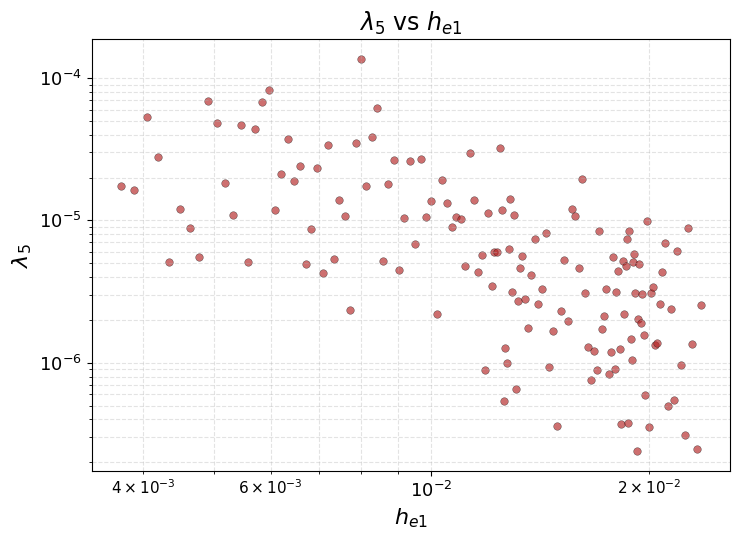

In [ ]:
plt.figure(figsize=(7.5, 5.5))

plt.scatter(
    h11mu_values, lambda5_values,
    s=30,
    color='firebrick',
    alpha=0.65,
    edgecolors='black',
    linewidths=0.3
)

plt.xscale('log')
plt.yscale('log')

plt.xlabel(r'$h_{e1}$', fontsize=16)
plt.ylabel(r'$\lambda_5$', fontsize=16)
plt.title(r'$\lambda_5$ vs $h_{e1}$', fontsize=17)

plt.grid(True, which='both', linestyle='--', alpha=0.35)

plt.tick_params(axis='both', which='major', labelsize=13)
plt.tick_params(axis='both', which='minor', labelsize=11)

plt.tight_layout()
plt.show()

In [ ]:
type(h11mu_values)

list

In [ ]:
len(h11mu_values)

146

# **Muon g-2**

## Membandingkan $Δa_\mu (scoto)$ dengan $\Delta a_\mu = a_\mu(exp) - a_\mu (MS)$

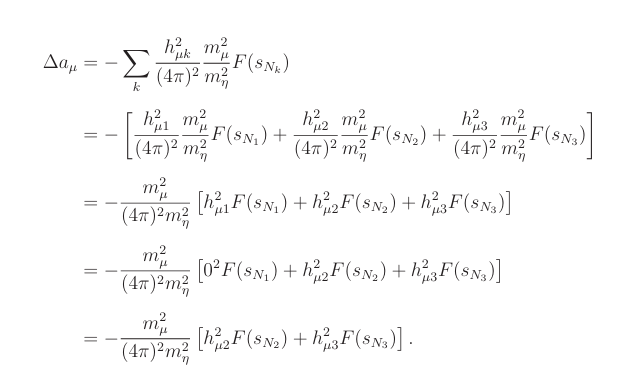

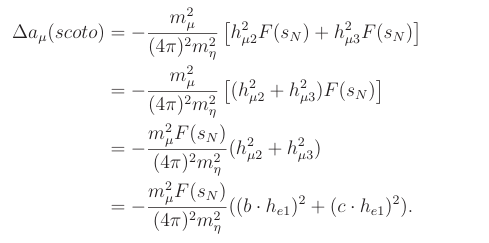

In [ ]:
amu_values = []
amu_all = []
he1_all = []
he1_values = []
sol1_values = []
sol2_values = []
c = []
b = []

mmu = 0.106 * 10**9 #GeV
delta_amu = 250 * 10 **(-11)
ralat = 48 * 10 **(-11)

def F2(x): #ini negatif
    return (1 - 6*x + 3*x**2 + 2*x**3 - 6*x**2 * log(x)) / (6 * (1 - x)**4)
def g2(mmu, meta, he1, pi, b, c):
    p = mmu**2 * ((b*he1)**2 + (c*he1)**2)
    q = (4*pi)**2 * meta**2
    return (-p/q)

#amu = symbols('amu', real=True, positive=True)
for i, entry in enumerate(dat_reshaped):
  if i>= len(h11mu_values):
    continue
  else:
    meta = entry[0]
    pi = entry[1]
    b = entry[6]
    c = entry[7]
    he1 = h11mu_values[i]
    he1_all.append(float(he1))

    x = mN**2 / meta**2
    amu = g2(mmu, meta, he1, pi, b, c) * (-F2(x))
    amu_all.append(float(amu))

    ralat_max = delta_amu + ralat
    ralat_min = delta_amu - ralat

    if amu <= ralat_max and amu >= ralat_min:
      amu_values.append(float(amu))
      he1_values.append(float(he1))
      print("he1:", he1_values[-1])
      print(r"$\delta a$:", amu_values[-1])
else:
   print("Model ini tidak dapat menjelaskan muon g-2")

Model ini tidak dapat menjelaskan muon g-2


## Mencari $a_\mu$ (scoto) vs $h_{e1}$

Disini jelasin amu_scoto = delta amu - amu_SM

In [ ]:
print("Jumlah amu_scoto:", len(amu_all))
print("Jumlah he1:", len(he1_all))

Jumlah amu_scoto: 146
Jumlah he1: 146


In [ ]:
tabel = pd.DataFrame({
    "No": range(1, len(amu_all) + 1),
    "amu_scotogenic": amu_all,
    "he1": he1_all
})

tabel

,No,amu_scotogenic,he1
0,1,6.978592e-13,0.003722
1,2,4.304494e-14,0.003883
2,3,4.784796e-14,0.004041
3,4,1.396514e-13,0.004195
4,5,9.007912e-14,0.004345
...,...,...,...
141,142,1.394500e-12,0.022383
142,143,1.095293e-12,0.022659
143,144,5.808482e-11,0.022950
144,145,1.261605e-12,0.023258


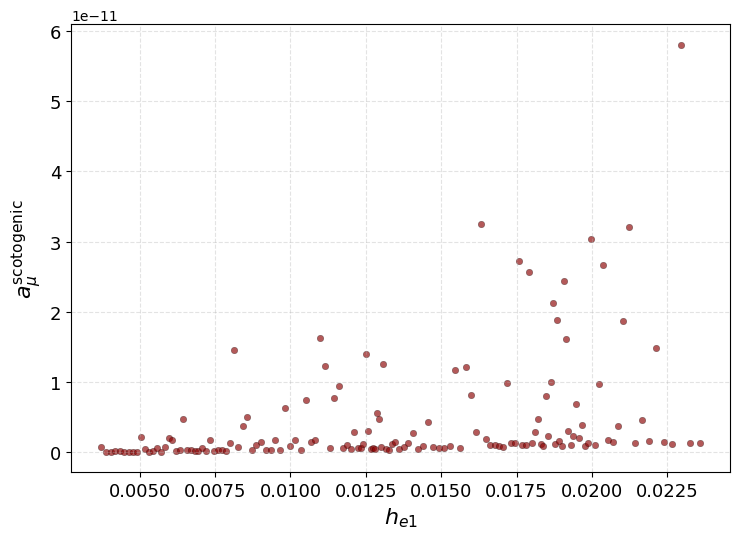

In [ ]:
plt.figure(figsize=(7.5, 5.5))

plt.scatter(
    he1_all,
    amu_all,
    s=22,
    color='darkred',
    alpha=0.65,
    edgecolors='black',
    linewidths=0.25
)

plt.xlabel(r"$h_{e1}$", fontsize=16)
plt.ylabel(r"$a_\mu^{\mathrm{scotogenic}}$", fontsize=16)

plt.grid(True, which="both", linestyle="--", alpha=0.35)

plt.tick_params(axis='both', which='major', labelsize=13)
plt.tick_params(axis='both', which='minor', labelsize=11)

plt.tight_layout()
plt.show()

## Membandingkan $a_\mu$ scotogenic, MS, dan eksperimen Fermilab

In [ ]:
print(min(amu_all), max(amu_all))

4.304493652377727e-14 5.8084818530394164e-11


In [ ]:
amu_MS = 116591811 * 10**(-11)
ralat_MS = 43 * 10**(-11)

amu_exp = 116592061 * 10**(-11)
ralat_exp = 18 * 10**(-11)

amu_MS_max = amu_MS + ralat_MS
amu_MS_min = amu_MS - ralat_MS

amu_exp_max = amu_exp + ralat_exp
amu_exp_min = amu_exp - ralat_exp

amu_scoto_max = max(amu_all)
amu_scoto_min = min(amu_all)

amu_scoto_max_fix = amu_scoto_max + amu_MS_max
amu_scoto_min_fix = amu_scoto_min + amu_MS_min

data = {
    "Sumber": ["Prediksi MS", "Eksperimen FERMILAB", "Model scotogenic"],
    "a_mu min": [amu_MS_min, amu_exp_min, amu_scoto_min_fix],
    "a_mu max": [amu_MS_max, amu_exp_max, amu_scoto_max_fix],
}

df_amu = pd.DataFrame(data)
df_amu

,Sumber,a_mu min,a_mu max
0,Prediksi MS,0.001166,0.001166
1,Eksperimen FERMILAB,0.001166,0.001166
2,Model scotogenic,0.001166,0.001166


In [ ]:
labels = ["Prediksi MS", "Eksperimen Fermilab", "Model scotogenic"]
y = np.arange(len(labels))

# central values
amu_central = [
    0.5*(amu_MS_max + amu_MS_min),
    0.5*(amu_exp_max + amu_exp_min),
    0.5*(amu_scoto_max_fix + amu_scoto_min_fix)
]

# errors
amu_err = [
    0.5*(amu_MS_max - amu_MS_min),
    0.5*(amu_exp_max - amu_exp_min),
    0.5*(amu_scoto_max_fix - amu_scoto_min_fix)
]

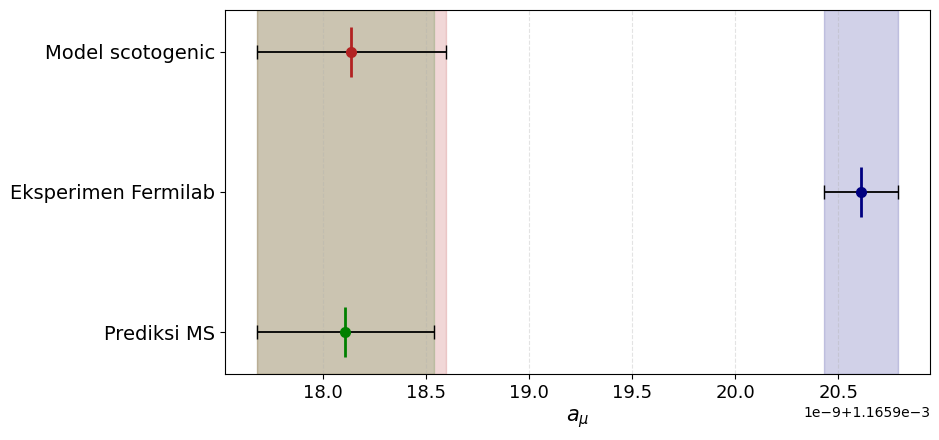

In [ ]:
fig, ax = plt.subplots(figsize=(9.5, 4.5))

colors = {
    "Prediksi MS": "green",
    "Eksperimen Fermilab": "navy",
    "Model scotogenic": "firebrick"
}

#vertical bands (min–max, full height)
for i, label in enumerate(labels):
    ax.axvspan(
        amu_central[i] - amu_err[i],
        amu_central[i] + amu_err[i],
        color=colors[label],
        alpha=0.18,
        zorder=0
    )

#error bars + central points
for i, label in enumerate(labels):
    ax.errorbar(
        amu_central[i], y[i],
        xerr=amu_err[i],
        fmt='o',
        color=colors[label],
        ecolor='black',
        elinewidth=1.3,
        capsize=5,
        markersize=7,
        zorder=2
    )

    #central tick (penanda ekstra)
    ax.vlines(
        amu_central[i],
        y[i] - 0.18,
        y[i] + 0.18,
        color=colors[label],
        linewidth=2.0,
        zorder=3
    )

ax.set_yticks(y)
ax.set_yticklabels(labels, fontsize=14)
ax.set_xlabel(r"$a_\mu$", fontsize=15)

ax.grid(axis='x', linestyle='--', alpha=0.35)

ax.tick_params(axis='x', which='major', labelsize=13)
ax.tick_params(axis='x', which='minor', labelsize=11)

plt.tight_layout()
plt.show()